<a href="https://colab.research.google.com/github/melekyakin/StockPriceForecastingLSTM/blob/main/garbage_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Waste Classification with CNNs & Transfer Learning

Automatic classification of waste images into **six material categories** (cardboard, glass, metal, paper, plastic, trash) using the TrashNet dataset.

This notebook compares two approaches under an identical evaluation protocol (one stratified split, a held-out test set used only once):

1. **Baseline CNN** trained from scratch
2. **MobileNetV2** transfer learning (frozen feature extractor → fine-tuning)

**Contents**

1. [Business problem](#1.-Business-problem)
2. [Setup & configuration](#2.-Setup-&-configuration)
3. [Data understanding](#3.-Data-understanding)
4. [Data preparation](#4.-Data-preparation)
5. [Modeling](#5.-Modeling)
6. [Evaluation](#6.-Evaluation)
7. [Explainability (Grad-CAM)](#7.-Explainability-(Grad-CAM))
8. [Error analysis](#8.-Error-analysis)
9. [Inference & export](#9.-Inference-&-export)
10. [Limitations & next steps](#10.-Limitations-&-next-steps)

## 1. Business problem

**Problem.** Waste management is central to reducing environmental pollution and raising recycling rates, but sorting waste by hand is slow, error-prone and expensive. Contamination in recycling streams lowers the value of recovered material and hurts plant efficiency.

**Solution.** An image classifier can automatically identify the material of a waste item, which can be used to drive sorting lines, smart bins, or recycling-education apps and reduce manual labour.

**Success criteria.**

- High **macro-averaged F1** (the dataset is imbalanced, so plain accuracy can hide poor performance on small classes such as *trash*).
- Reliable performance on a **held-out test set** that is never used for training or model selection.
- A model small and fast enough to be deployed on modest hardware.

## 2. Setup & configuration

All tunable values live in a single `Config` object so experiments are easy to reproduce and modify.

**Dataset location.** The notebook auto-detects the dataset in these places (in order): the `GARBAGE_DATA_DIR` environment variable, Google Drive (Colab), `/kaggle/input`, and `./data`. The folder must contain one sub-folder per class (`cardboard/`, `glass/`, ...). Nested folders (as in the Kaggle download) are handled automatically.

In [1]:
import importlib.util
import json
import os
import re
import time
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print(f"TensorFlow {tf.__version__} | GPUs available: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow 2.21.0 | GPUs available: 1


In [2]:
@dataclass(frozen=True)
class Config:
    seed: int = 42
    img_size: tuple = (224, 224)
    batch_size: int = 32
    val_size: float = 0.15          # fraction of the full dataset
    test_size: float = 0.15         # fraction of the full dataset
    baseline_epochs: int = 40       # upper bound; early stopping decides
    head_epochs: int = 15           # transfer learning: train the new classifier head
    finetune_epochs: int = 15       # transfer learning: fine-tune the top of the backbone
    finetune_layers: int = 30       # number of backbone layers to unfreeze
    learning_rate: float = 1e-3
    finetune_lr: float = 1e-5


CFG = Config()

CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

ARTIFACTS_DIR = Path("artifacts")   # trained models, metrics (git-ignored)
ASSETS_DIR = Path("assets")         # figures used in the README
ARTIFACTS_DIR.mkdir(exist_ok=True)
ASSETS_DIR.mkdir(exist_ok=True)

# Reproducibility: seeds Python, NumPy and TensorFlow at once.
keras.utils.set_random_seed(CFG.seed)
AUTOTUNE = tf.data.AUTOTUNE


def save_fig(name):
    """Save the current figure to assets/ so it can be embedded in the README."""
    plt.savefig(ASSETS_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [3]:
# --- Locate the dataset --------------------------------------------------------
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

CANDIDATE_DIRS = [
    os.environ.get("GARBAGE_DATA_DIR"),
    "/content/drive/MyDrive/Garbage classification",
    "/kaggle/input",
    "data",
]


def find_dataset_root(candidates, class_names):
    """Return the folder that directly contains one sub-folder per class."""
    for candidate in filter(None, candidates):
        if not os.path.isdir(candidate):
            continue
        for dirpath, dirnames, _ in os.walk(candidate):
            if set(class_names).issubset(dirnames):
                return Path(dirpath)
    raise FileNotFoundError(
        "Dataset not found. Download it from "
        "https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification, "
        "unzip it into ./data, or set the GARBAGE_DATA_DIR environment variable."
    )


def list_images(root, class_names):
    """Build a DataFrame with one row per image: path, class name, integer label."""
    rows = []
    for label, name in enumerate(class_names):
        for path in sorted((root / name).iterdir()):
            if path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append((str(path), name, label))
    return pd.DataFrame(rows, columns=["path", "class_name", "label"])


DATA_ROOT = find_dataset_root(CANDIDATE_DIRS, CLASS_NAMES)
df = list_images(DATA_ROOT, CLASS_NAMES)
print(f"Dataset root : {DATA_ROOT}")
print(f"Total images : {len(df)}")

Mounted at /content/drive
Dataset root : /content/drive/MyDrive/Garbage classification
Total images : 2530


## 3. Data understanding

**TrashNet** was created by Gary Thung and Mindy Yang at Stanford University. The original release contains **2,527 images**; the Kaggle mirror used here contains **2,530** (a few extra glass, metal and plastic images). Class sizes in the mirror:

| Class | Images |
|---|---|
| Paper | 594 |
| Glass | 502 |
| Plastic | 483 |
| Metal | 411 |
| Cardboard | 403 |
| Trash | 137 |

Objects were photographed on a white poster board under sunlight or room lighting. Images are RGB and roughly 512 × 384 pixels.

Source: [Kaggle mirror](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification) · [Original repository](https://github.com/garythung/trashnet)

### 3.1 Class distribution

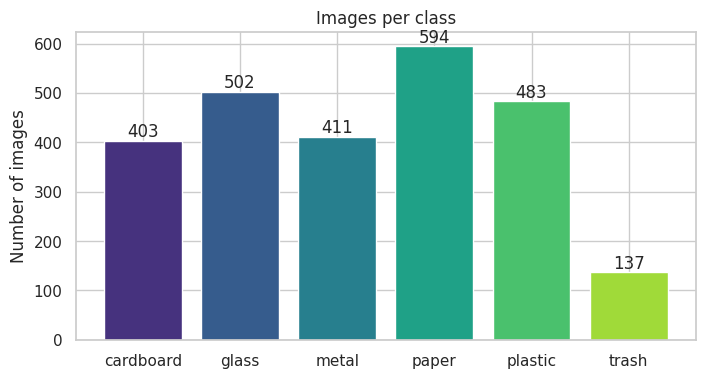

Imbalance ratio (largest / smallest class): 4.3x


In [4]:
counts = df["class_name"].value_counts().reindex(CLASS_NAMES)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.values, color=sns.color_palette("viridis", len(counts)))
ax.bar_label(ax.containers[0])
ax.set_title("Images per class")
ax.set_ylabel("Number of images")
save_fig("class_distribution")
plt.show()

print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}x")

The *trash* class is roughly 4–5× smaller than the others. We will address this with **class weights** during training and by reporting **macro-averaged** metrics.

### 3.2 Sample images

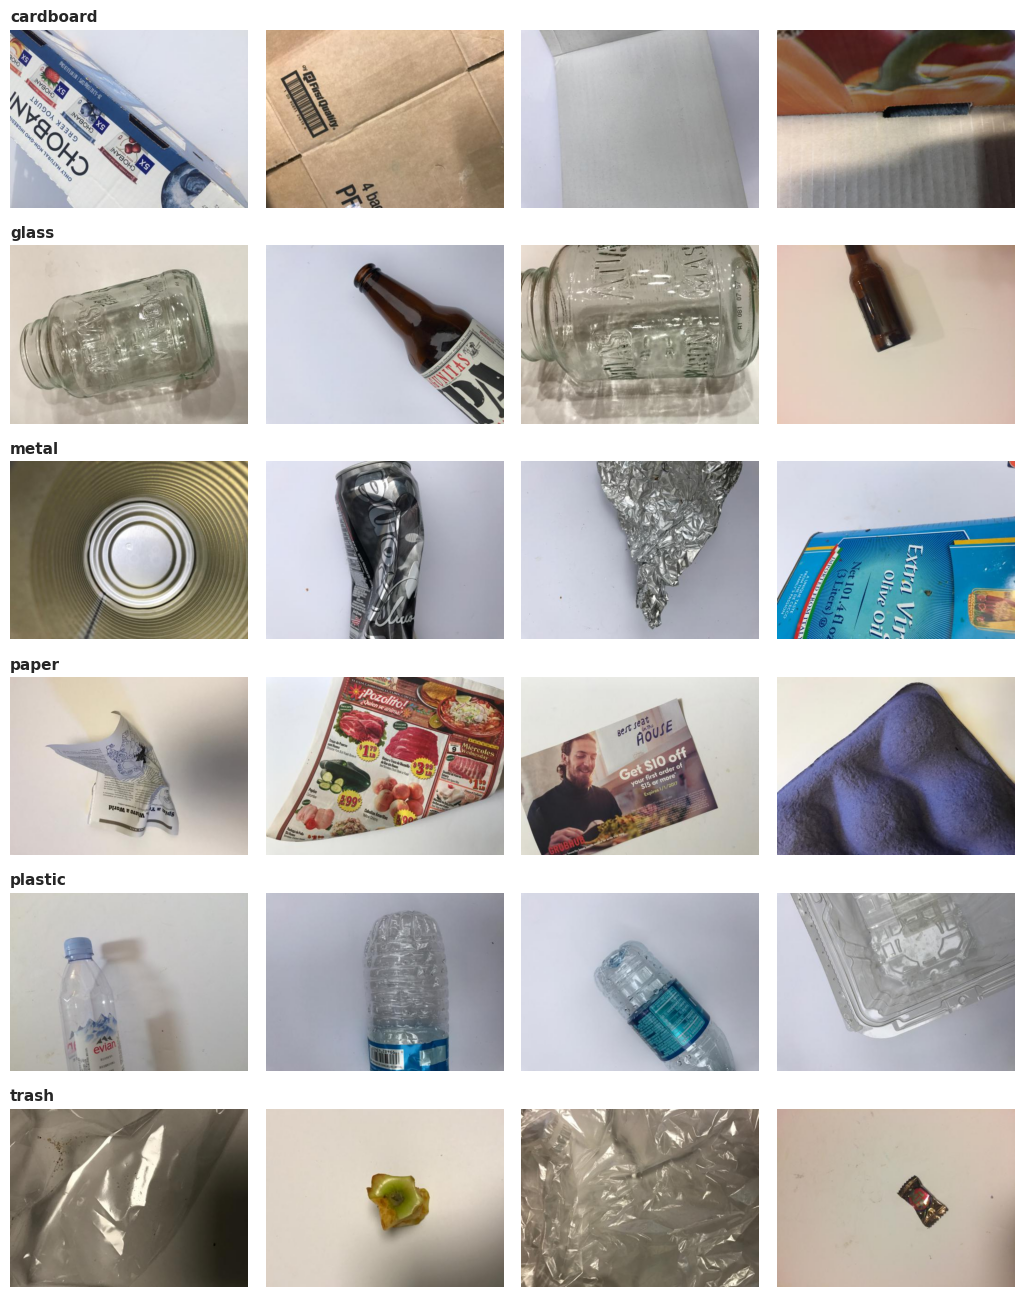

In [5]:
def show_samples(frame, per_class=4):
    fig, axes = plt.subplots(NUM_CLASSES, per_class, figsize=(per_class * 2.6, NUM_CLASSES * 2.2))
    for row, name in enumerate(CLASS_NAMES):
        subset = frame[frame["class_name"] == name].sample(per_class, random_state=CFG.seed)
        for col, path in enumerate(subset["path"]):
            ax = axes[row, col]
            with Image.open(path) as im:
                ax.imshow(im)
            ax.axis("off")
            if col == 0:
                ax.set_title(name, loc="left", fontsize=11, fontweight="bold")
    plt.tight_layout()


show_samples(df)
save_fig("sample_images")
plt.show()

### 3.3 Image size check

In [6]:
def image_size(path):
    with Image.open(path) as im:
        return im.size


size_counts = Counter(image_size(p) for p in df["path"].sample(300, random_state=CFG.seed))
print("Most common (width, height) in a 300-image sample:", size_counts.most_common(3))

Most common (width, height) in a 300-image sample: [((512, 384), 300)]


## 4. Data preparation

### 4.1 Stratified train / validation / test split

A key design decision: the data is split **once**, **stratified by class**, into three disjoint sets.

| Split | Purpose |
|---|---|
| Train (70%) | fit model weights |
| Validation (15%) | early stopping, learning-rate scheduling, model selection |
| Test (15%) | final, unbiased performance estimate — touched only in Section 6 |

Using a separate test set avoids the common pitfall of selecting and reporting on the same data.
> **Caveat.** TrashNet may contain several photos of the same physical object taken from different angles. A random split can therefore place near-duplicates in both train and test, which can make test scores optimistic (see *Limitations*).

In [7]:
holdout_frac = CFG.val_size + CFG.test_size

train_df, holdout_df = train_test_split(
    df, test_size=holdout_frac, stratify=df["label"], random_state=CFG.seed
)
val_df, test_df = train_test_split(
    holdout_df,
    test_size=CFG.test_size / holdout_frac,
    stratify=holdout_df["label"],
    random_state=CFG.seed,
)

# Sanity check: the splits must be disjoint.
assert not (set(train_df["path"]) & set(val_df["path"]))
assert not (set(train_df["path"]) & set(test_df["path"]))
assert not (set(val_df["path"]) & set(test_df["path"]))

split_summary = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val": val_df["class_name"].value_counts(),
    "test": test_df["class_name"].value_counts(),
}).reindex(CLASS_NAMES)
split_summary.loc["total"] = split_summary.sum()
split_summary

,train,val,test
class_name,,,
cardboard,282,61,60
glass,351,75,76
metal,288,61,62
paper,416,89,89
plastic,338,72,73
trash,96,21,20
total,1771,379,380


### 4.2 Class weights

Class weights make errors on under-represented classes count more during training.

In [8]:
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].to_numpy())
class_weights = dict(enumerate(weights))
print({CLASS_NAMES[i]: round(w, 2) for i, w in class_weights.items()})

{'cardboard': np.float64(1.05), 'glass': np.float64(0.84), 'metal': np.float64(1.02), 'paper': np.float64(0.71), 'plastic': np.float64(0.87), 'trash': np.float64(3.07)}


### 4.3 Input pipeline (`tf.data`)

Images are decoded and resized **once**, cached in memory as `uint8` (~380 MB for the full dataset), then batched and prefetched. Random data augmentation is applied **inside the model** (see Section 5), so it runs on the GPU and is automatically disabled at inference time.

In [9]:
def decode_and_resize(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, CFG.img_size)
    image = tf.cast(tf.round(image), tf.uint8)   # compact representation for caching
    image.set_shape((*CFG.img_size, 3))
    return image, label


def make_dataset(frame, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["path"].to_numpy(), frame["label"].to_numpy().astype("int32"))
    )
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(frame), seed=CFG.seed, reshuffle_each_iteration=True)
    ds = ds.batch(CFG.batch_size)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)   # not shuffled: order matches test_df

images, labels = next(iter(train_ds))
print("Batch:", images.shape, images.dtype, "| labels:", labels.shape)

Batch: (32, 224, 224, 3) <dtype: 'float32'> | labels: (32,)


## 5. Modeling

Both models share the same augmentation block and the same training recipe:

- **Loss:** sparse categorical cross-entropy, with class weights
- **Optimizer:** Adam
- **Callbacks:** early stopping (restores the best weights), learning-rate reduction on plateau, best-model checkpointing

### 5.1 Shared building blocks

In [10]:
def build_augmentation():
    """Random augmentations; active only during training."""
    return keras.Sequential(
        [
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
            layers.RandomContrast(0.1),
        ],
        name="augmentation",
    )


def make_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            ARTIFACTS_DIR / f"{name}.keras", monitor="val_loss", save_best_only=True
        ),
    ]


def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


def plot_history(histories, name, stage_boundary=None):
    """Plot accuracy and loss curves; `histories` is a list of History objects (one per stage)."""
    merged = {key: [] for key in ("accuracy", "val_accuracy", "loss", "val_loss")}
    for history in histories:
        for key in merged:
            merged[key] += history.history[key]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, (train_key, val_key, title) in zip(
        axes, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]
    ):
        ax.plot(merged[train_key], label="Train")
        ax.plot(merged[val_key], label="Validation")
        if stage_boundary is not None:
            ax.axvline(stage_boundary - 0.5, ls="--", color="gray", label="Start of fine-tuning")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.set_title(f"{name}: {title}")
        ax.legend()
    plt.tight_layout()
    save_fig(f"training_curves_{name}")
    plt.show()

### 5.2 Baseline: CNN from scratch

Four convolution blocks (Conv → BatchNorm → ReLU → MaxPool) followed by global average pooling. Compared with a plain `Flatten` + large dense layers, global pooling drastically reduces the parameter count and the risk of overfitting on a small dataset.

In [11]:
def build_baseline_cnn():
    inputs = keras.Input(shape=(*CFG.img_size, 3))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255, name="preprocess")(x)
    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")


baseline = build_baseline_cnn()
compile_model(baseline, CFG.learning_rate)
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 250,534 (978.65 KB)

 Trainable params: 249,830 (975.90 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.4003 - loss: 1.5443 - val_accuracy: 0.2296 - val_loss: 1.8114 - learning_rate: 0.0010
Epoch 2/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - accuracy: 0.4647 - loss: 1.3619 - val_accuracy: 0.1636 - val_loss: 2.0374 - learning_rate: 0.0010
Epoch 3/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 131ms/step - accuracy: 0.4811 - loss: 1.3186 - val_accuracy: 0.2322 - val_loss: 1.9776 - learning_rate: 0.0010
Epoch 4/40
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.4689 - loss: 1.3238
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - accuracy: 0.4687 - loss: 1.3035 - val_accuracy: 0.2032 - val_loss: 2.0481 - learning_rate: 0.0010
Epoch 5/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.5144 - loss: 1.2008 - val_accuracy: 0.1609 - val_loss: 1.9687 - learning_rate: 5.0000e-04
Epoch 6/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 131ms/step - accuracy: 0.5494 - loss: 1.1775 

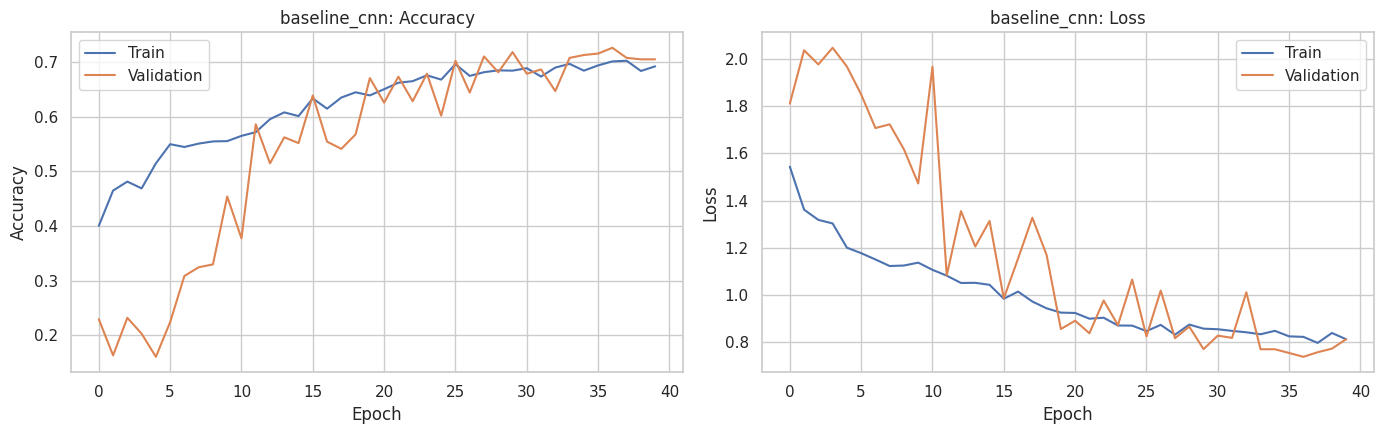

In [12]:
history_baseline = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG.baseline_epochs,
    class_weight=class_weights,
    callbacks=make_callbacks("baseline_cnn"),
)
plot_history([history_baseline], "baseline_cnn")

### 5.3 Transfer learning: MobileNetV2

MobileNetV2 pre-trained on ImageNet is a small, fast backbone well suited to deployment. Training happens in two stages:

1. **Feature extraction** — freeze the backbone and train only the new classification head.
2. **Fine-tuning** — unfreeze the top of the backbone and continue training with a much lower learning rate. BatchNorm layers stay frozen to keep their statistics stable on this small dataset.

> The first run downloads the ImageNet weights, so an internet connection is required.

In [13]:
def build_transfer_model():
    base = keras.applications.MobileNetV2(
        input_shape=(*CFG.img_size, 3),
        include_top=False,
        weights="imagenet",
        name="mobilenetv2_base",
    )
    base.trainable = False

    inputs = keras.Input(shape=(*CFG.img_size, 3))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="preprocess")(x)   # MobileNetV2 expects [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_classifier"), base


def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


transfer, base_model = build_transfer_model()
compile_model(transfer, CFG.learning_rate)
print(f"Total parameters: {transfer.count_params():,} | trainable: {count_trainable(transfer):,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Total parameters: 2,265,670 | trainable: 7,686


In [14]:
# Stage 1: train the classification head only.
history_head = transfer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG.head_epochs,
    class_weight=class_weights,
    callbacks=make_callbacks("mobilenetv2_head"),
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 12s 111ms/step - accuracy: 0.4766 - loss: 1.4006 - val_accuracy: 0.6675 - val_loss: 0.8717 - learning_rate: 0.0010
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.6776 - loss: 0.8847 - val_accuracy: 0.7177 - val_loss: 0.7300 - learning_rate: 0.0010
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.7250 - loss: 0.7459 - val_accuracy: 0.7625 - val_loss: 0.6641 - learning_rate: 0.0010
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.7696 - loss: 0.6538 - val_accuracy: 0.7652 - val_loss: 0.6282 - learning_rate: 0.0010
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.7832 - loss: 0.5915 - val_accuracy: 0.7916 - val_loss: 0.6006 - learning_rate: 0.0010
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.7899 - loss: 0.5684 - val_accuracy: 0.7704 - val_loss: 0.5961 - learning_rate: 0.0010
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.8137 - loss: 0.5307 - val_a

Trainable parameters after unfreezing: 1,518,406
Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 13s 131ms/step - accuracy: 0.8571 - loss: 0.3897 - val_accuracy: 0.8470 - val_loss: 0.4906 - learning_rate: 1.0000e-05
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.8814 - loss: 0.3418 - val_accuracy: 0.8338 - val_loss: 0.4765 - learning_rate: 1.0000e-05
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.8842 - loss: 0.3293 - val_accuracy: 0.8338 - val_loss: 0.4597 - learning_rate: 1.0000e-05
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.8769 - loss: 0.3387 - val_accuracy: 0.8391 - val_loss: 0.4693 - learning_rate: 1.0000e-05
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - accuracy: 0.8865 - loss: 0.3096 - val_accuracy: 0.8364 - val_loss: 0.4428 - learning_rate: 1.0000e-05
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.9040 - loss: 0.2724 - val_accuracy: 0.8338 - val_loss: 0.4483 - learning_rate: 1.0000e-05
Epoch 7/15
56/56 ━━

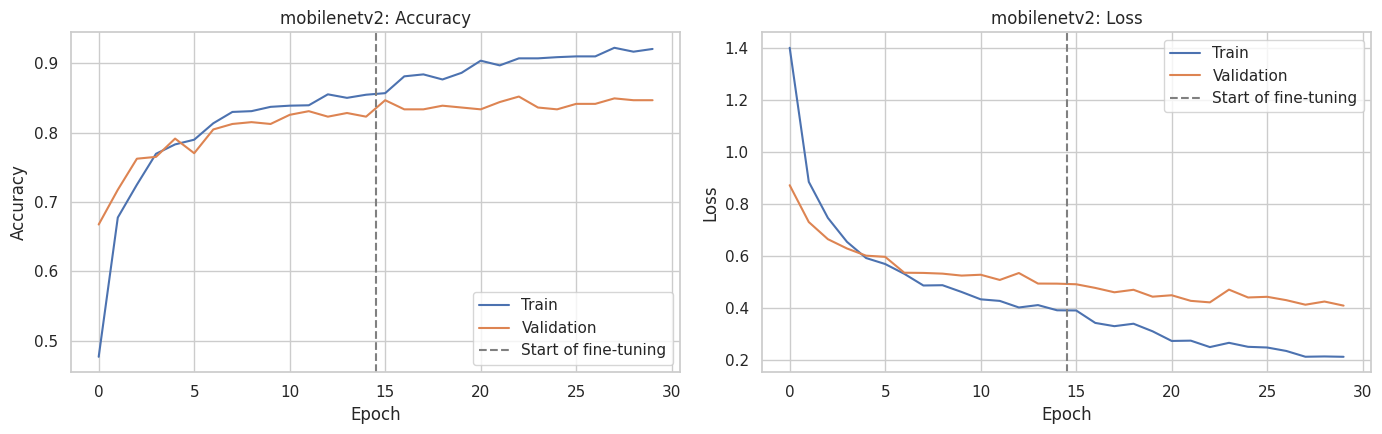

In [15]:
# Stage 2: fine-tune the top of the backbone with a low learning rate.
base_model.trainable = True
for layer in base_model.layers[: -CFG.finetune_layers]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(transfer, CFG.finetune_lr)   # must re-compile after changing `trainable`
print(f"Trainable parameters after unfreezing: {count_trainable(transfer):,}")

history_finetune = transfer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG.finetune_epochs,
    class_weight=class_weights,
    callbacks=make_callbacks("mobilenetv2_finetune"),
)

plot_history(
    [history_head, history_finetune],
    "mobilenetv2",
    stage_boundary=len(history_head.history["loss"]),
)

## 6. Evaluation

Both models are scored on the **validation set** (used only to decide which model to export) and **once** on the untouched **test set** (used only for the final report). Because the classes are imbalanced, we focus on **macro-averaged** metrics (every class counts equally) alongside accuracy.

Besides predictive quality, we also record deployment-relevant numbers: parameter counts, saved model size and single-image inference latency.

In [16]:
y_val = val_df["label"].to_numpy()
y_true = test_df["label"].to_numpy()   # test_ds is not shuffled, so the order matches


def score(model, ds, y):
    """Predict on `ds` and return (metrics, probabilities, predicted labels)."""
    probs = model.predict(ds, verbose=0)
    preds = probs.argmax(axis=1)
    metrics = {
        "accuracy": accuracy_score(y, preds),
        "macro_precision": precision_score(y, preds, average="macro", zero_division=0),
        "macro_recall": recall_score(y, preds, average="macro", zero_division=0),
        "macro_f1": f1_score(y, preds, average="macro"),
        "weighted_f1": f1_score(y, preds, average="weighted"),
    }
    return metrics, probs, preds


def latency_ms(model, n_warmup=2):
    """Mean single-image forward-pass time (batch size 1) on the current runtime."""
    batch = next(iter(test_ds))[0].numpy()
    for i in range(n_warmup):
        model(batch[i:i + 1], training=False)
    start = time.perf_counter()
    for i in range(n_warmup, len(batch)):
        model(batch[i:i + 1], training=False)
    return (time.perf_counter() - start) / (len(batch) - n_warmup) * 1000


def file_mb(path):
    return path.stat().st_size / 1e6 if path.exists() else float("nan")


models = {"baseline_cnn": baseline, "mobilenetv2": transfer}
checkpoints = {"baseline_cnn": "baseline_cnn.keras", "mobilenetv2": "mobilenetv2_finetune.keras"}

val_results, results, all_probs, all_preds, efficiency = {}, {}, {}, {}, {}
for name, model in models.items():
    val_results[name], _, _ = score(model, val_ds, y_val)
    results[name], all_probs[name], all_preds[name] = score(model, test_ds, y_true)
    efficiency[name] = {
        "parameters": int(model.count_params()),
        "trainable_parameters": count_trainable(model),
        "size_mb": file_mb(ARTIFACTS_DIR / checkpoints[name]),
        "latency_ms": latency_ms(model),
    }

HARDWARE = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
comparison = pd.DataFrame(results).T.join(pd.DataFrame(efficiency).T)
for col in ("parameters", "trainable_parameters"):
    comparison[col] = comparison[col].astype(int)
print(f"Test-set metrics | latency measured on {HARDWARE}")
comparison.round(4)

Test-set metrics | latency measured on GPU


,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,parameters,trainable_parameters,size_mb,latency_ms
baseline_cnn,0.7316,0.7136,0.7576,0.7173,0.7347,250534,249830,3.1083,19.4248
mobilenetv2,0.8447,0.8324,0.8398,0.8352,0.8450,2265670,1518406,21.8211,180.8874


In [17]:
for name in models:
    print(f"\n=== {name} ===")
    print(classification_report(y_true, all_preds[name], target_names=CLASS_NAMES, digits=3))


=== baseline_cnn ===
              precision    recall  f1-score   support

   cardboard      0.900     0.900     0.900        60
       glass      0.741     0.566     0.642        76
       metal      0.750     0.774     0.762        62
       paper      0.793     0.775     0.784        89
     plastic      0.697     0.630     0.662        73
       trash      0.400     0.900     0.554        20

    accuracy                          0.732       380
   macro avg      0.714     0.758     0.717       380
weighted avg      0.753     0.732     0.735       380


=== mobilenetv2 ===
              precision    recall  f1-score   support

   cardboard      0.927     0.850     0.887        60
       glass      0.831     0.842     0.837        76
       metal      0.824     0.903     0.862        62
       paper      0.897     0.876     0.886        89
     plastic      0.789     0.767     0.778        73
       trash      0.727     0.800     0.762        20

    accuracy                      

### 6.1 Confusion matrices

The left panel shows raw counts, the right panel shows each row normalised by class size (i.e. per-class recall).

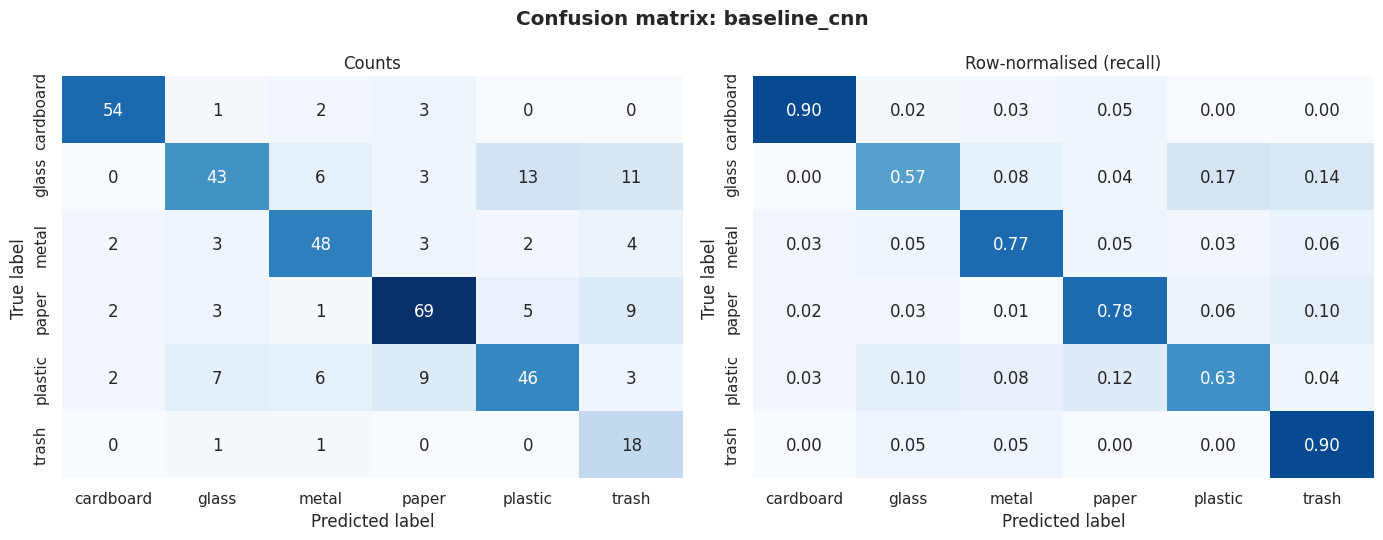

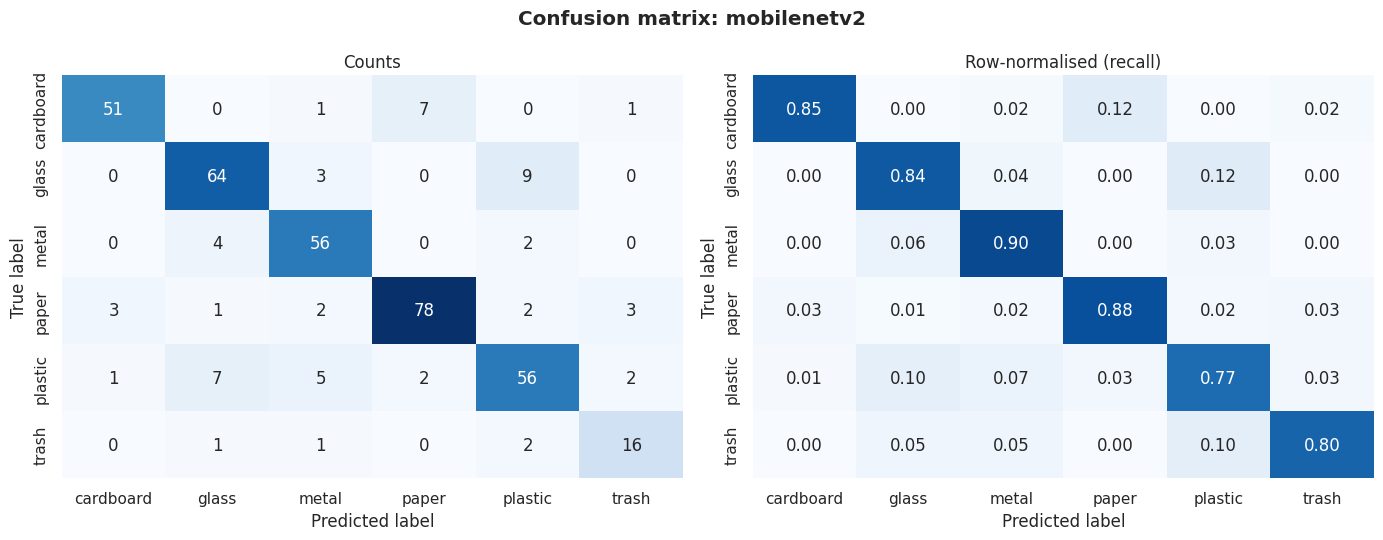

In [18]:
def plot_confusion(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
    axes[0].set_title("Counts")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
    axes[1].set_title("Row-normalised (recall)")
    for ax in axes:
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
    fig.suptitle(f"Confusion matrix: {name}", fontweight="bold")
    plt.tight_layout()
    save_fig(f"confusion_matrix_{name}")
    plt.show()


for name in models:
    plot_confusion(y_true, all_preds[name], name)

In [19]:
# Model selection uses the VALIDATION set only; the test set is just reported.
best_name = max(val_results, key=lambda k: val_results[k]["macro_f1"])
best_model = models[best_name]
best_probs, best_preds = all_probs[best_name], all_preds[best_name]
print(
    f"Selected by validation macro-F1: {best_name} "
    f"(val {val_results[best_name]['macro_f1']:.4f} | test {results[best_name]['macro_f1']:.4f})"
)

Selected by validation macro-F1: mobilenetv2 (val 0.8181 | test 0.8352)


## 7. Explainability (Grad-CAM)

Accuracy numbers say *how often* the model is right, not *why*. **Grad-CAM** highlights the image regions that most influenced a prediction. This helps verify that the model looks at the object rather than at background artefacts (an important check on a dataset photographed on a uniform white board).

Grad-CAM is computed here for the MobileNetV2 model.

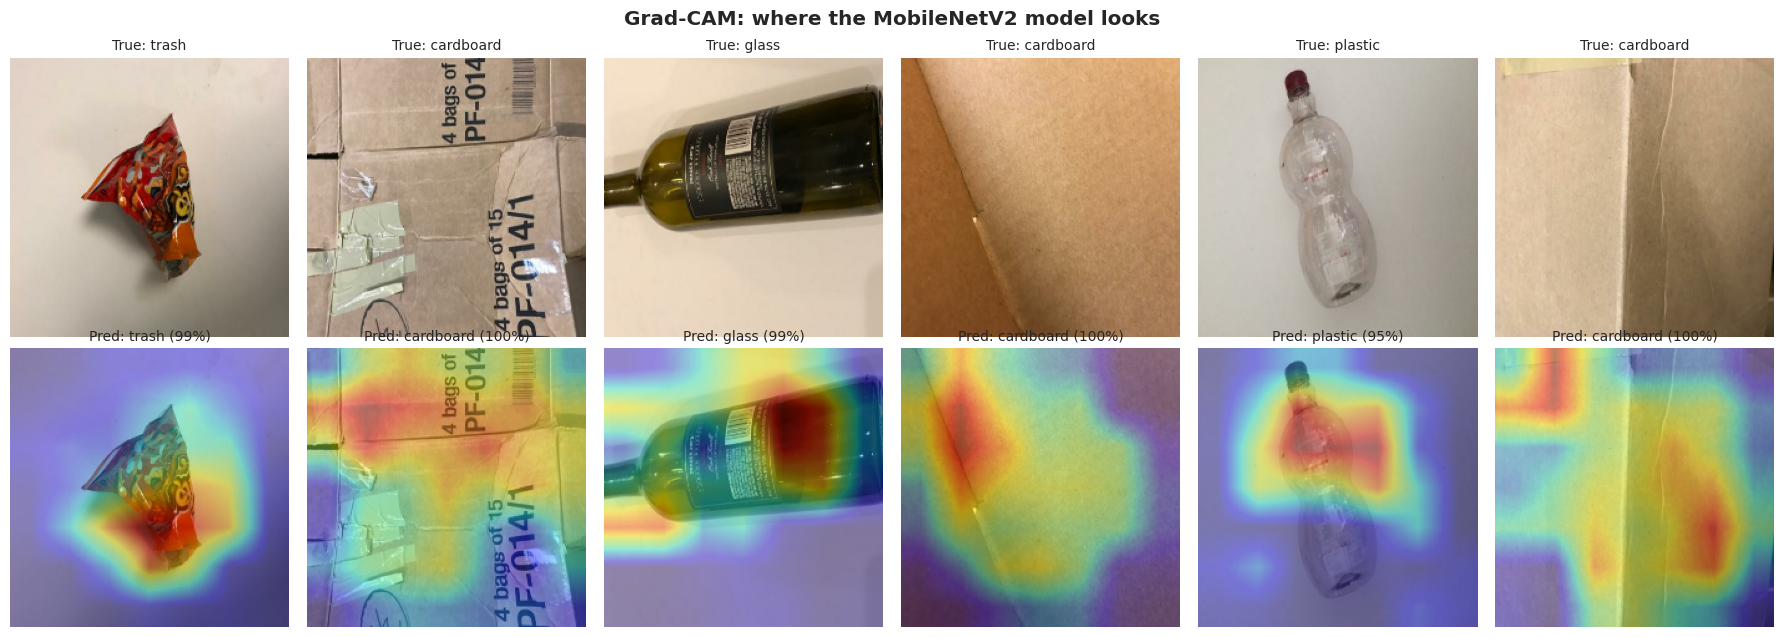

In [20]:
def load_image(path):
    """Load an image as a float32 array in [0, 255] with the model's input size."""
    raw = tf.io.read_file(str(path))
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    return tf.image.resize(image, CFG.img_size).numpy().astype("float32")


def grad_cam(image, model, backbone, class_idx=None):
    """Return (heatmap in [0, 1], predicted class index, class probabilities)."""
    x = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    x = model.get_layer("preprocess")(x)
    with tf.GradientTape() as tape:
        features = backbone(x, training=False)      # (1, 7, 7, 1280) last conv feature maps
        tape.watch(features)
        pooled = model.get_layer("gap")(features)
        probs = model.get_layer("predictions")(pooled)
        if class_idx is None:
            class_idx = int(tf.argmax(probs[0]))
        score = probs[:, class_idx]
    grads = tape.gradient(score, features)
    channel_weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(channel_weights * features, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), class_idx, probs[0].numpy()


samples = test_df.sample(6, random_state=CFG.seed)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for col, (_, row) in enumerate(samples.iterrows()):
    image = load_image(row["path"])
    cam, pred_idx, probs = grad_cam(image, transfer, base_model)
    heatmap = tf.image.resize(cam[..., None], CFG.img_size).numpy().squeeze()

    axes[0, col].imshow(image.astype("uint8"))
    axes[0, col].set_title(f"True: {row['class_name']}", fontsize=10)
    axes[1, col].imshow(image.astype("uint8"))
    axes[1, col].imshow(heatmap, cmap="jet", alpha=0.4)
    axes[1, col].set_title(f"Pred: {CLASS_NAMES[pred_idx]} ({probs[pred_idx]:.0%})", fontsize=10)
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.suptitle("Grad-CAM: where the MobileNetV2 model looks", fontweight="bold")
plt.tight_layout()
save_fig("gradcam_examples")
plt.show()

## 8. Error analysis

Looking at the **most confident mistakes** of the best model is often the fastest way to find label noise, ambiguous categories (e.g. cardboard vs. paper) or systematic failure modes.

59 of 380 test images misclassified by mobilenetv2


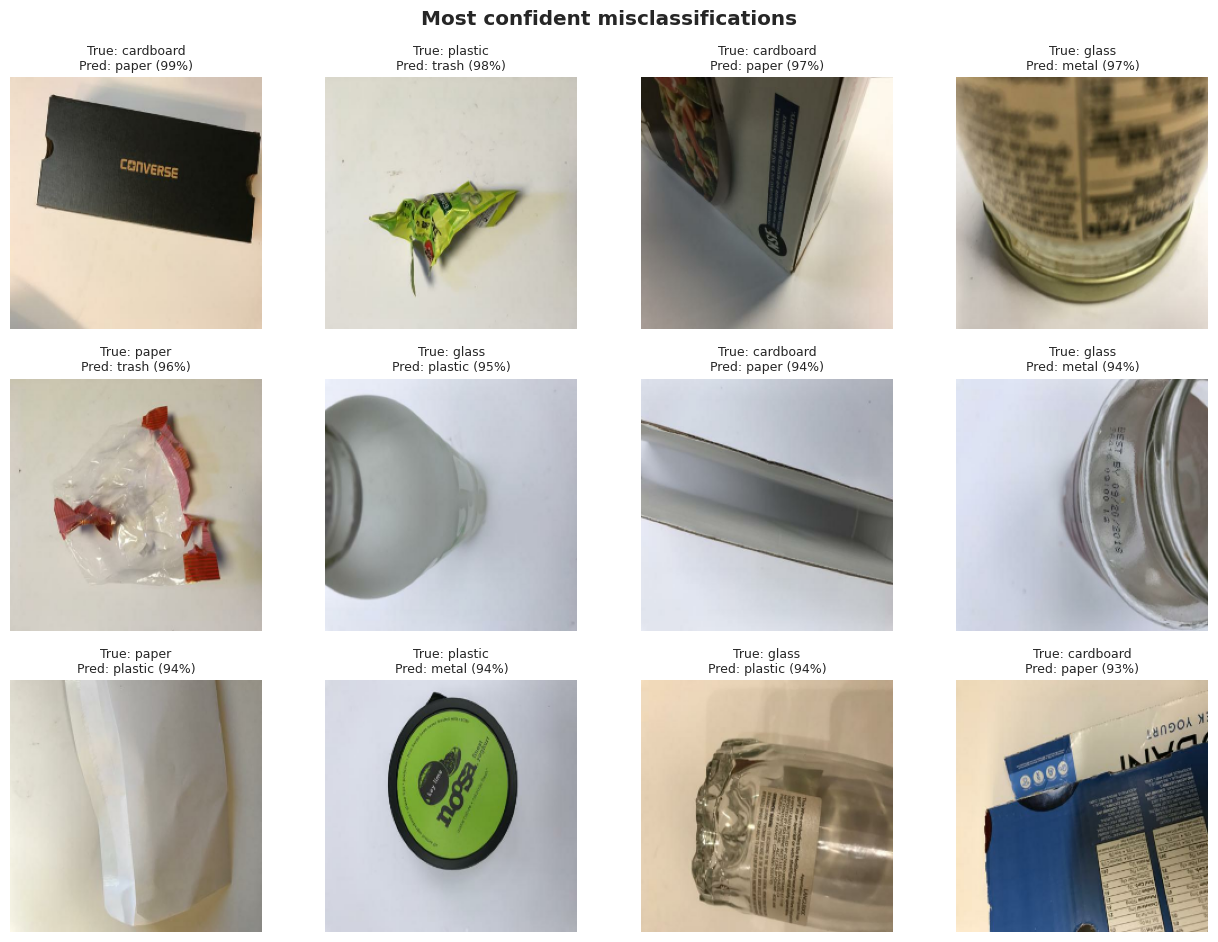

In [21]:
wrong = np.flatnonzero(best_preds != y_true)
print(f"{len(wrong)} of {len(y_true)} test images misclassified by {best_name}")

if len(wrong):
    # Sort mistakes by the model's confidence, highest first.
    chosen = wrong[np.argsort(-best_probs[wrong].max(axis=1))][:12]
    n_cols = 4
    n_rows = int(np.ceil(len(chosen) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.2, n_rows * 3.2), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, idx in zip(axes.ravel(), chosen):
        ax.imshow(load_image(test_df.iloc[idx]["path"]).astype("uint8"))
        ax.set_title(
            f"True: {CLASS_NAMES[y_true[idx]]}\n"
            f"Pred: {CLASS_NAMES[best_preds[idx]]} ({best_probs[idx].max():.0%})",
            fontsize=9,
        )
    plt.suptitle("Most confident misclassifications", fontweight="bold")
    plt.tight_layout()
    save_fig("misclassified_examples")
    plt.show()

### 8.1 Random test predictions

A random (not cherry-picked) sample of test images with the true label, the predicted label and the model's confidence. Green = correct, red = wrong.

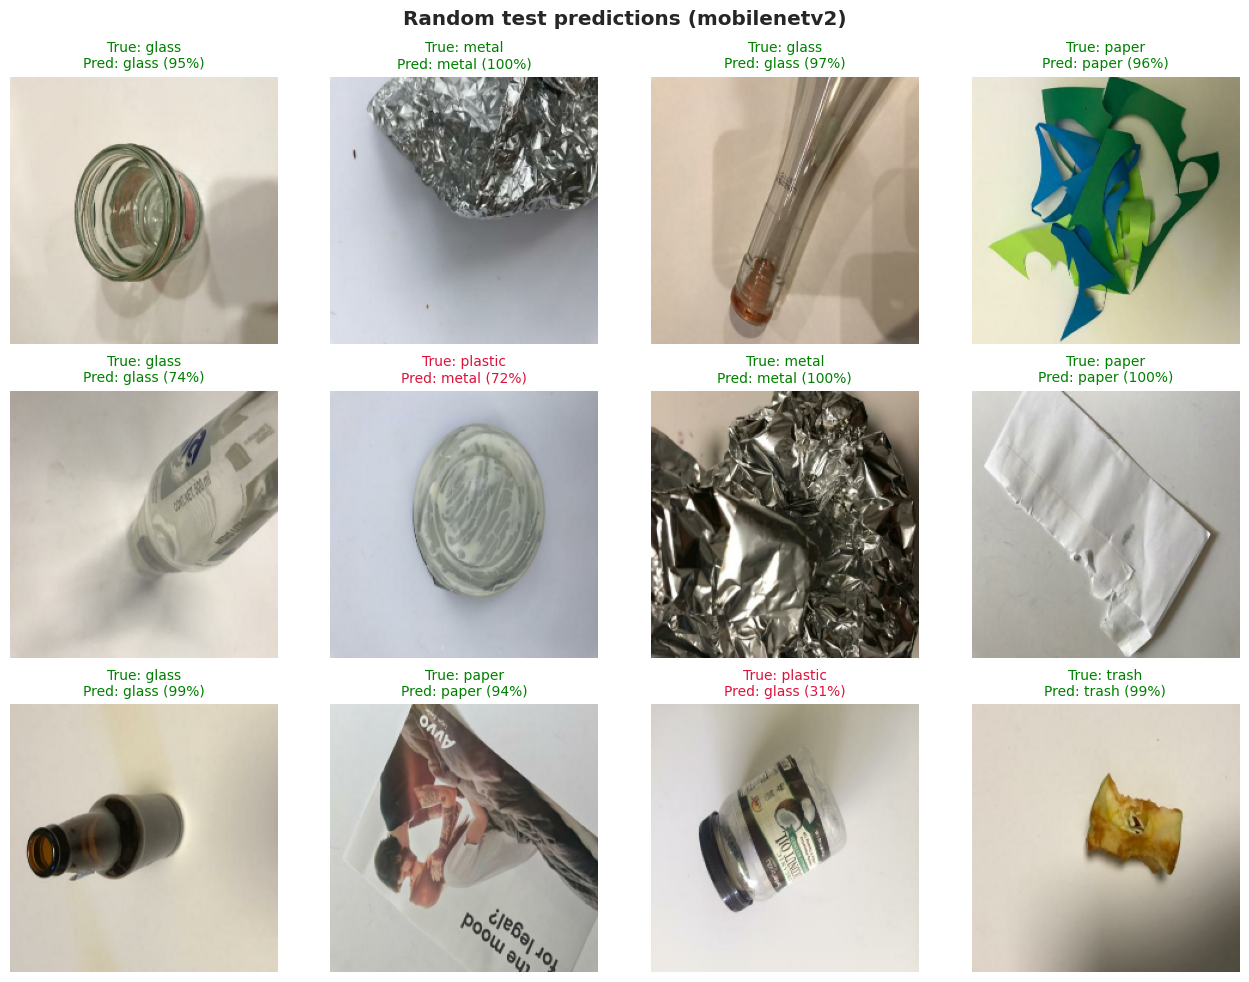

In [22]:
rng = np.random.default_rng(CFG.seed)
idx = rng.choice(len(test_df), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, k in zip(axes.ravel(), idx):
    ax.imshow(load_image(test_df.iloc[k]["path"]).astype("uint8"))
    ax.axis("off")
    correct = best_preds[k] == y_true[k]
    ax.set_title(
        f"True: {CLASS_NAMES[y_true[k]]}\nPred: {CLASS_NAMES[best_preds[k]]} ({best_probs[k].max():.0%})",
        fontsize=10, color="green" if correct else "crimson",
    )
plt.suptitle(f"Random test predictions ({best_name})", fontweight="bold")
plt.tight_layout()
save_fig("sample_predictions")
plt.show()

## 9. Inference & export

### 9.1 Predicting a single image

True class: metal


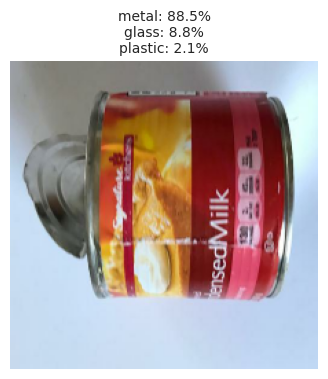

[('metal', 0.8850205540657043),
 ('glass', 0.08825179934501648),
 ('plastic', 0.02090870589017868)]

In [23]:
def predict_image(path, model, top_k=3, show=True):
    """Classify one image file and return the top-k (class, probability) pairs."""
    image = load_image(path)
    probs = model.predict(image[None, ...], verbose=0)[0]
    top = np.argsort(probs)[::-1][:top_k]
    ranking = [(CLASS_NAMES[i], float(probs[i])) for i in top]
    if show:
        plt.figure(figsize=(4, 4))
        plt.imshow(image.astype("uint8"))
        plt.axis("off")
        plt.title("\n".join(f"{name}: {p:.1%}" for name, p in ranking), fontsize=10)
        plt.show()
    return ranking


example_path = test_df.iloc[0]["path"]
print("True class:", test_df.iloc[0]["class_name"])
predict_image(example_path, best_model)

### 9.2 Saving artifacts

The best model (selected by validation macro-F1) is saved in the native Keras format together with the class names and the test metrics. Data augmentation and input scaling are part of the model, so downstream code only needs to pass in a 224 × 224 RGB image with pixel values in `[0, 255]`.

In [24]:
best_path = ARTIFACTS_DIR / "best_model.keras"
best_model.save(best_path)
(ARTIFACTS_DIR / "class_names.json").write_text(json.dumps(CLASS_NAMES, indent=2))
(ARTIFACTS_DIR / "metrics.json").write_text(
    json.dumps(
        {
            "best_model": best_name,
            "selection_criterion": "validation macro-F1",
            "validation_metrics": val_results,
            "test_metrics": results,
            "efficiency": efficiency,
            "latency_hardware": HARDWARE,
        },
        indent=2,
        default=float,
    )
)

# Sanity check: the reloaded model must reproduce the same predictions.
reloaded = keras.models.load_model(best_path)
batch = np.stack([load_image(p) for p in test_df["path"].head(8)])
assert np.allclose(best_model.predict(batch, verbose=0), reloaded.predict(batch, verbose=0), atol=1e-4)
print(f"Saved and verified: {best_path} ({best_path.stat().st_size / 1e6:.1f} MB)")

Saved and verified: artifacts/best_model.keras (21.8 MB)


In [25]:
# Optional: TensorFlow Lite export with dynamic-range quantisation
# (weights stored as int8, activations stay float32; no representative dataset is used,
#  so this is NOT full-integer INT8 quantisation).
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    tflite_path = ARTIFACTS_DIR / "garbage_classifier.tflite"
    tflite_path.write_bytes(tflite_model)

    # Benchmark: latency and prediction agreement with the Keras model.
    interpreter = tf.lite.Interpreter(model_content=tflite_model)
    interpreter.allocate_tensors()
    inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
    sample = next(iter(test_ds))[0].numpy()

    def run_tflite(x):
        interpreter.set_tensor(inp["index"], x[None, ...].astype("float32"))
        interpreter.invoke()
        return interpreter.get_tensor(out["index"])[0]

    run_tflite(sample[0])   # warm-up
    start = time.perf_counter()
    tflite_probs = np.stack([run_tflite(x) for x in sample])
    tflite_ms = (time.perf_counter() - start) / len(sample) * 1000
    agreement = float((tflite_probs.argmax(1) == best_model.predict(sample, verbose=0).argmax(1)).mean())

    tflite_stats = {"size_mb": len(tflite_model) / 1e6, "latency_ms": tflite_ms, "agreement_with_keras": agreement}
    metrics_path = ARTIFACTS_DIR / "metrics.json"
    saved = json.loads(metrics_path.read_text())
    saved["tflite"] = tflite_stats
    metrics_path.write_text(json.dumps(saved, indent=2, default=float))
    print(f"TFLite: {tflite_stats['size_mb']:.1f} MB | {tflite_ms:.1f} ms/image ({HARDWARE} host) | "
          f"agreement with Keras on {len(sample)} images: {agreement:.0%}")
except Exception as exc:  # the converter is sensitive to TF / Keras version combinations
    print(f"TFLite export skipped: {exc}")

Saved artifact at '/tmp/tmpgr5tmmji'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_183')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  134765681861136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681863248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681852496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681864592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681861328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681858640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681864976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681864784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681858448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134765681867472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1347656818

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite: 2.5 MB | 18.2 ms/image (GPU host) | agreement with Keras on 32 images: 100%
